Breast cancer gene-expression analysis.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

In [6]:
project_folder = Path.cwd().parent
data_folder = project_folder / "data"
output_folder = project_folder / "result"

output_folder.mkdir(parents=True, exist_ok=True)

print("Data folder exists:", data_folder.exists())
print("Results folder:", output_folder)

Data folder exists: True
Results folder: c:\Users\NUMB1\Desktop\breast cancer bio\result


In [7]:
file_path = data_folder / "GSE70905_series_matrix (1).txt"

print(file_path.exists())

True


In [8]:
data = pd.read_csv(
    file_path,
    sep="\t",
    comment="!"
)

print(data.shape)
print(data.head())

(45015, 138)
   ID_REF  GSM1821512  GSM1821513  GSM1821514  GSM1821515  GSM1821516  \
0       1      16.274         NaN         NaN      15.772      18.096   
1       2         NaN       6.683       6.491       6.834       6.486   
2       3       6.745       6.677       6.797       6.707       6.612   
3       4       6.553       6.792       6.705       6.665       6.559   
4       5       6.661       6.676       6.546       6.581       6.454   

   GSM1821517  GSM1821518  GSM1821519  GSM1821520  ...  GSM1821639  \
0      15.685      16.450      17.021      16.450  ...      16.460   
1       6.670         NaN       6.539       6.750  ...       6.683   
2       6.703       6.649       6.740       6.976  ...       6.600   
3       6.680       6.671       6.644       6.761  ...       6.673   
4       6.682       6.304       6.604       6.752  ...       6.636   

   GSM1821640  GSM1821641  GSM1821642  GSM1821643  GSM1821644  GSM1821645  \
0      13.884         NaN      17.373         NaN 

In [9]:
annotation_path = data_folder / "GPL4133_old_annotations.txt"

print(annotation_path.exists())

True


In [10]:
annotation = pd.read_csv(
    annotation_path,
    sep="\t",
    skiprows=21,
    low_memory=False
)

print(annotation.shape)
print(annotation.columns.tolist())

(45220, 20)
['ID', 'COL', 'ROW', 'NAME', 'SPOT_ID', 'CONTROL_TYPE', 'REFSEQ', 'GB_ACC', 'GENE', 'GENE_SYMBOL', 'GENE_NAME', 'UNIGENE_ID', 'ENSEMBL_ID', 'TIGR_ID', 'ACCESSION_STRING', 'CHROMOSOMAL_LOCATION', 'CYTOBAND', 'DESCRIPTION', 'GO_ID', 'SEQUENCE']


In [11]:
expression = data.drop(columns=["ID_REF"])

print(expression.shape)

(45015, 137)


In [12]:
normal = expression.iloc[:, :47]

tumor = expression.iloc[:, 47:94]

print(normal.shape)
print(tumor.shape)

(45015, 47)
(45015, 47)


In [13]:
with open(file_path, "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith("!Sample_characteristics_ch1") and "tissue:" in line:
            tissues = [
                item.strip().strip('"').replace("tissue: ", "")
                for item in line.strip().split("\t")[1:]
            ]

            print(pd.Series(tissues).value_counts())
            break

normal       47
tumor        47
reduction    43
Name: count, dtype: int64


In [14]:
with open(file_path, "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith("!Sample_title"):
            titles = [
                item.strip().strip('"')
                for item in line.strip().split("\t")[1:]
            ]

            print("First 5 samples:")
            print(titles[:5])

            print("\nSamples 45 to 50:")
            print(titles[44:50])

            print("\nSamples 90 to 95:")
            print(titles[89:95])

            print("\nLast 5 samples:")
            print(titles[-5:])
            break
        

First 5 samples:
['CM001-normal', 'CM009-normal', 'CM010-normal', 'CM011-normal', 'CM013-normal']

Samples 45 to 50:
['CMG24-normal', 'CMG28-normal', 'CMG43-normal', 'CM001-tumor', 'CM009-tumor', 'CM010-tumor']

Samples 90 to 95:
['CMG15-tumor', 'CMG23-tumor', 'CMG24-tumor', 'CMG28-tumor', 'CMG43-tumor', 'RP001-reduction']

Last 5 samples:
['RP064-reduction', 'RP065-reduction', 'RP066-reduction', 'RP067-reduction', 'RP070-reduction']


In [15]:
print("Number of sample titles:", len(titles))
print("Number of expression columns:", expression.shape[1])

print("\nFirst 5 expression column IDs:")
print(expression.columns[:5].tolist())

print("\nLast 5 expression column IDs:")
print(expression.columns[-5:].tolist())

Number of sample titles: 137
Number of expression columns: 137

First 5 expression column IDs:
['GSM1821512', 'GSM1821513', 'GSM1821514', 'GSM1821515', 'GSM1821516']

Last 5 expression column IDs:
['GSM1821644', 'GSM1821645', 'GSM1821646', 'GSM1821647', 'GSM1821648']


In [16]:
sample_info = pd.DataFrame({
    "GSM_ID": expression.columns,
    "Sample_title": titles
})

print(sample_info.head())
print("\nSamples around the group boundaries:")
print(sample_info.iloc[[0, 46, 47, 93, 94, 136]])

       GSM_ID  Sample_title
0  GSM1821512  CM001-normal
1  GSM1821513  CM009-normal
2  GSM1821514  CM010-normal
3  GSM1821515  CM011-normal
4  GSM1821516  CM013-normal

Samples around the group boundaries:
         GSM_ID     Sample_title
0    GSM1821512     CM001-normal
46   GSM1821558     CMG43-normal
47   GSM1821559      CM001-tumor
93   GSM1821605      CMG43-tumor
94   GSM1821606  RP001-reduction
136  GSM1821648  RP070-reduction


In [17]:
normal_mean = normal.mean(axis=1)
tumor_mean = tumor.mean(axis=1)

difference = tumor_mean - normal_mean

all_results = pd.DataFrame({
    "Probe_ID": data["ID_REF"],
    "Normal_mean": normal_mean,
    "Tumor_mean": tumor_mean,
    "Difference": difference
})

print(all_results.shape)
print(all_results.head())

(45015, 4)
   Probe_ID  Normal_mean  Tumor_mean  Difference
0         1    15.978515   15.994000    0.015485
1         2     6.669167    6.720341    0.051175
2         3     6.740415    6.667333   -0.073081
3         4     6.713024    6.661182   -0.051843
4         5     6.677175    6.720581    0.043406


In [18]:
print("Number of IDs in data:", data["ID_REF"].nunique())
print("Number of IDs in annotation:", annotation["ID"].nunique())

matched_ids = data["ID_REF"].isin(annotation["ID"])

print("Matched probes:", matched_ids.sum())
print("Unmatched probes:", (~matched_ids).sum())

Number of IDs in data: 45015
Number of IDs in annotation: 45220
Matched probes: 45015
Unmatched probes: 0


In [19]:
all_results_annotated = all_results.merge(
    annotation[["ID", "GENE_SYMBOL", "GENE_NAME"]],
    left_on="Probe_ID",
    right_on="ID",
    how="left"
)

print(all_results_annotated.shape)

print(
    all_results_annotated[
        ["Probe_ID", "GENE_SYMBOL", "GENE_NAME",
         "Normal_mean", "Tumor_mean", "Difference"]
    ].head()
)


(45015, 7)
   Probe_ID GENE_SYMBOL GENE_NAME  Normal_mean  Tumor_mean  Difference
0         1         NaN       NaN    15.978515   15.994000    0.015485
1         2         NaN       NaN     6.669167    6.720341    0.051175
2         3         NaN       NaN     6.740415    6.667333   -0.073081
3         4         NaN       NaN     6.713024    6.661182   -0.051843
4         5         NaN       NaN     6.677175    6.720581    0.043406


In [20]:
print(
    "Probes with gene symbols:",
    all_results_annotated["GENE_SYMBOL"].notna().sum()
)

print(
    "Probes without gene symbols:",
    all_results_annotated["GENE_SYMBOL"].isna().sum()
)

Probes with gene symbols: 32576
Probes without gene symbols: 12439


In [21]:
normal_ids = []
tumor_ids = []

for title in sample_info["Sample_title"]:
    if title.endswith("-normal"):
        normal_ids.append(title.replace("-normal", ""))
    elif title.endswith("-tumor"):
        tumor_ids.append(title.replace("-tumor", ""))

print(set(normal_ids) == set(tumor_ids))

True


In [22]:
print(len(normal_ids))
print(len(tumor_ids))
print(len(set(normal_ids)))
print(len(set(tumor_ids)))

47
47
47
47


In [23]:
print(
    "Patient IDs match in the same order:",
    normal_ids == tumor_ids
)

assert normal_ids == tumor_ids, (
    "Normal and tumor samples are not paired in the same order."
)

Patient IDs match in the same order: True


In [24]:
from scipy.stats import ttest_rel

assert len(normal_ids) == 47, "Expected 47 normal samples."
assert len(tumor_ids) == 47, "Expected 47 tumor samples."
assert normal_ids == tumor_ids, (
    "Normal and tumor samples are not paired in the same order."
)
assert normal.shape == tumor.shape, (
    "Normal and tumor expression matrices must have the same shape."
)

t_stat, p_value_paired = ttest_rel(
    np.asarray(tumor, dtype=float),
    np.asarray(normal, dtype=float),
    axis=1,
    nan_policy="omit"
)

print("Paired t-tests completed.")
print("Patient pairs:", len(normal_ids))
print("Probes tested:", len(p_value_paired))
print("Valid p-values:", np.isfinite(p_value_paired).sum())

Paired t-tests completed.
Patient pairs: 47
Probes tested: 45015
Valid p-values: 45015


In [25]:
p_values = np.asarray(p_value_paired, dtype=float)

all_results_annotated["p_value_paired"] = p_values

valid = np.isfinite(p_values)
fdr_values = np.full(len(p_values), np.nan)

fdr_values[valid] = multipletests(
    p_values[valid],
    method="fdr_bh"
)[1]

all_results_annotated["FDR_paired"] = fdr_values

print("Paired p-values stored.")
print("Valid p-values:", valid.sum())
print("Significant probes (FDR < 0.05):",
      (fdr_values < 0.05).sum())

Paired p-values stored.
Valid p-values: 45015
Significant probes (FDR < 0.05): 20246


In [26]:
all_results_annotated["p_value_paired"] = p_value_paired

normal_values = np.asarray(normal, dtype=float)
tumor_values = np.asarray(tumor, dtype=float)

pair_valid = np.isfinite(normal_values) & np.isfinite(tumor_values)
pair_counts = pair_valid.sum(axis=1)

normal_sums = np.where(pair_valid, normal_values, 0).sum(axis=1)
tumor_sums = np.where(pair_valid, tumor_values, 0).sum(axis=1)

normal_pair_mean = np.divide(
    normal_sums,
    pair_counts,
    out=np.full(len(pair_counts), np.nan),
    where=pair_counts > 0
)

tumor_pair_mean = np.divide(
    tumor_sums,
    pair_counts,
    out=np.full(len(pair_counts), np.nan),
    where=pair_counts > 0
)

all_results_annotated["Normal_mean"] = normal_pair_mean
all_results_annotated["Tumor_mean"] = tumor_pair_mean
all_results_annotated["Difference"] = tumor_pair_mean - normal_pair_mean

print("Paired p-values stored.")
print("Mean differences updated using matched observations.")
print("Probes with at least one complete pair:", (pair_counts > 0).sum())

Paired p-values stored.
Mean differences updated using matched observations.
Probes with at least one complete pair: 45015


In [27]:
significant = all_results_annotated[
    all_results_annotated["FDR_paired"] < 0.05
]

print(len(significant))

20246


In [28]:
print(data.isna().sum().sum())

152247


In [29]:
print(data.isna().sum(axis=1).gt(0).sum())

38584


In [30]:
paired_data = expression.iloc[:, :94]

complete_probes = paired_data.notna().all(axis=1)

print(complete_probes.sum())

11379


In [31]:
missing_per_probe = paired_data.isna().sum(axis=1)

print(missing_per_probe.value_counts().sort_index())

0     11379
1     12874
2      8034
3      4473
4      2535
5      1484
6       987
7       679
8       494
9       466
10      314
11      260
12      194
13      125
14      130
15       90
16       52
17       70
18       41
19       36
20       45
21       30
22       34
23       23
24       21
25       17
26       12
27       10
28       12
29       10
30       10
31        9
32        8
33        6
34       10
36        7
37        6
38        2
39        1
40        1
41        5
42        2
43        5
45        2
46        1
47        1
50        2
51        1
52        1
55        1
57        1
60        1
65        1
Name: count, dtype: int64


In [32]:
complete_pairs = normal.notna() & tumor.notna()
pairs_per_probe = complete_pairs.sum(axis=1)

print(pairs_per_probe.describe())

count    45015.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
dtype: float64


In [33]:
print(data.iloc[:, 1:].describe().loc[["min", "max", "mean"]])

      GSM1821512  GSM1821513  GSM1821514  GSM1821515  GSM1821516  GSM1821517  \
min      5.05700    5.594000     4.57900    4.723000    5.242000    6.311000   
max     18.34200   24.993000    18.58600   18.407000   18.954000   18.279000   
mean     8.75871    8.731885     8.76214    8.754105    8.746832    8.747196   

      GSM1821518  GSM1821519  GSM1821520  GSM1821521  ...  GSM1821639  \
min     3.728000    5.316000    5.355000    3.753000  ...    5.788000   
max    18.684000   18.455000   18.677000   18.443000  ...   18.404000   
mean    8.726673    8.695551    8.719816    8.769781  ...    8.773145   

      GSM1821640  GSM1821641  GSM1821642  GSM1821643  GSM1821644  GSM1821645  \
min     4.903000    3.596000    5.028000    4.889000    5.858000    4.313000   
max    21.451000   19.256000   18.605000   21.350000   18.608000   21.119000   
mean    8.752009    8.774272    8.765619    8.726144    8.721525    8.753372   

      GSM1821646  GSM1821647  GSM1821648  
min     4.870000    5.

In [34]:
with open(file_path, "r", encoding="utf-8") as file:
    for line in file:
        if "data_processing" in line.lower():
            print(line)

!Sample_data_processing	"Expression data were background-corrected and quantile normalized using limma in R. Features flagged as non-uniform or below-background were excluded. Batch effect from Scan Date was corrected using ComBat."	"Expression data were background-corrected and quantile normalized using limma in R. Features flagged as non-uniform or below-background were excluded. Batch effect from Scan Date was corrected using ComBat."	"Expression data were background-corrected and quantile normalized using limma in R. Features flagged as non-uniform or below-background were excluded. Batch effect from Scan Date was corrected using ComBat."	"Expression data were background-corrected and quantile normalized using limma in R. Features flagged as non-uniform or below-background were excluded. Batch effect from Scan Date was corrected using ComBat."	"Expression data were background-corrected and quantile normalized using limma in R. Features flagged as non-uniform or below-background wer

In [35]:
top10 = significant.sort_values("FDR_paired").head(10)

top10[["Probe_ID", "GENE_SYMBOL", "Difference", "FDR_paired"]]

,Probe_ID,GENE_SYMBOL,Difference,FDR_paired
19251,19252,SSB,1.515277,3.761293e-16
11951,11952,KIAA1609,-1.060638,1.005935e-15
20213,20214,DUSP9,-2.542894,1.136072e-15
17194,17195,NaN,2.536468,1.898588e-15
35803,35804,NaN,2.503467,3.546520e-15
25930,25931,NaN,2.611652,3.697676e-15
15088,15089,NaN,-2.702128,7.932882e-15
25085,25086,CXCL5,-4.175182,7.932882e-15
28557,28558,GRIK3,2.927170,7.932882e-15
21371,21372,NaN,-1.248391,7.932882e-15


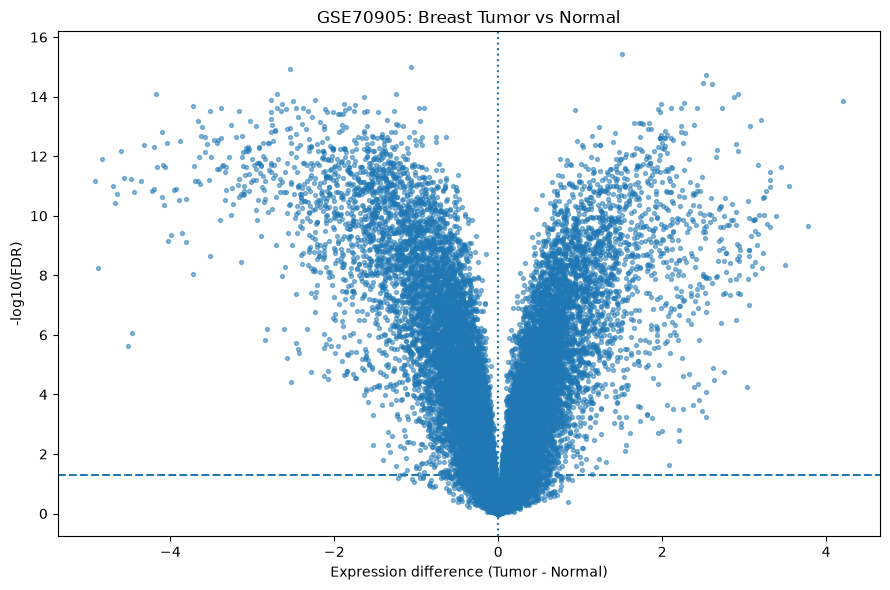

In [36]:
plot_data = all_results_annotated.dropna(
    subset=["Difference", "FDR_paired"]
).copy()

plot_data["minus_log10_FDR"] = -np.log10(
    plot_data["FDR_paired"].clip(lower=1e-300)
)

plt.figure(figsize=(9, 6))

plt.scatter(
    plot_data["Difference"],
    plot_data["minus_log10_FDR"],
    s=8,
    alpha=0.5
)

plt.axhline(-np.log10(0.05), linestyle="--")
plt.axvline(0, linestyle=":")

plt.xlabel("Expression difference (Tumor - Normal)")
plt.ylabel("-log10(FDR)")
plt.title("GSE70905: Breast Tumor vs Normal")

plt.tight_layout()

plt.savefig(
    output_folder / "volcano_plot_python.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [37]:
p_values = all_results_annotated["p_value_paired"]

valid_p_values = p_values.dropna()

print("Total probes:", len(p_values))
print("Valid p-values:", len(valid_p_values))
print("Missing p-values:", p_values.isna().sum())

Total probes: 45015
Valid p-values: 45015
Missing p-values: 0


In [38]:
fdr = all_results_annotated["FDR_paired"]

print("Missing FDR values:", fdr.isna().sum())
print("FDR values below 0:", (fdr < 0).sum())
print("FDR values above 1:", (fdr > 1).sum())

Missing FDR values: 0
FDR values below 0: 0
FDR values above 1: 0


In [39]:
print("All patient pairs match in order:", normal_ids == tumor_ids)

All patient pairs match in order: True


In [40]:
final_genes = significant[
    significant["GENE_SYMBOL"].notna()
].sort_values("FDR_paired")

final_genes[
    ["GENE_SYMBOL", "Difference", "p_value_paired", "FDR_paired"]
].head(20)

,GENE_SYMBOL,Difference,p_value_paired,FDR_paired
19251,SSB,1.515277,8.355643e-21,3.761293e-16
11951,KIAA1609,-1.060638,4.469331e-20,1.005935e-15
20213,DUSP9,-2.542894,7.571293e-20,1.136072e-15
25085,CXCL5,-4.175182,1.677826e-18,7.932882e-15
28557,GRIK3,2.927170,1.247884e-18,7.932882e-15
32377,DKFZp434F142,2.876533,2.424678e-18,9.922445e-15
22388,ZMYM6,-1.642500,2.659448e-18,9.976253e-15
15251,LOC26010,4.201723,5.039611e-18,1.417863e-14
20871,SLC25A28,-2.507444,4.954002e-18,1.417863e-14
8507,PCDHAC1,1.984111,7.421238e-18,1.751458e-14


In [41]:
all_results_annotated.to_csv(
    output_folder / "limma_free_python_results.csv",
    index=False
)

significant.to_csv(
    output_folder / "significant_genes_python.csv",
    index=False
)

final_genes.to_csv(
    output_folder / "significant_annotated_genes.csv",
    index=False
)

top10.to_csv(
    output_folder / "top_10_significant_probes.csv",
    index=False
)

print("Final result tables saved.")

Final result tables saved.


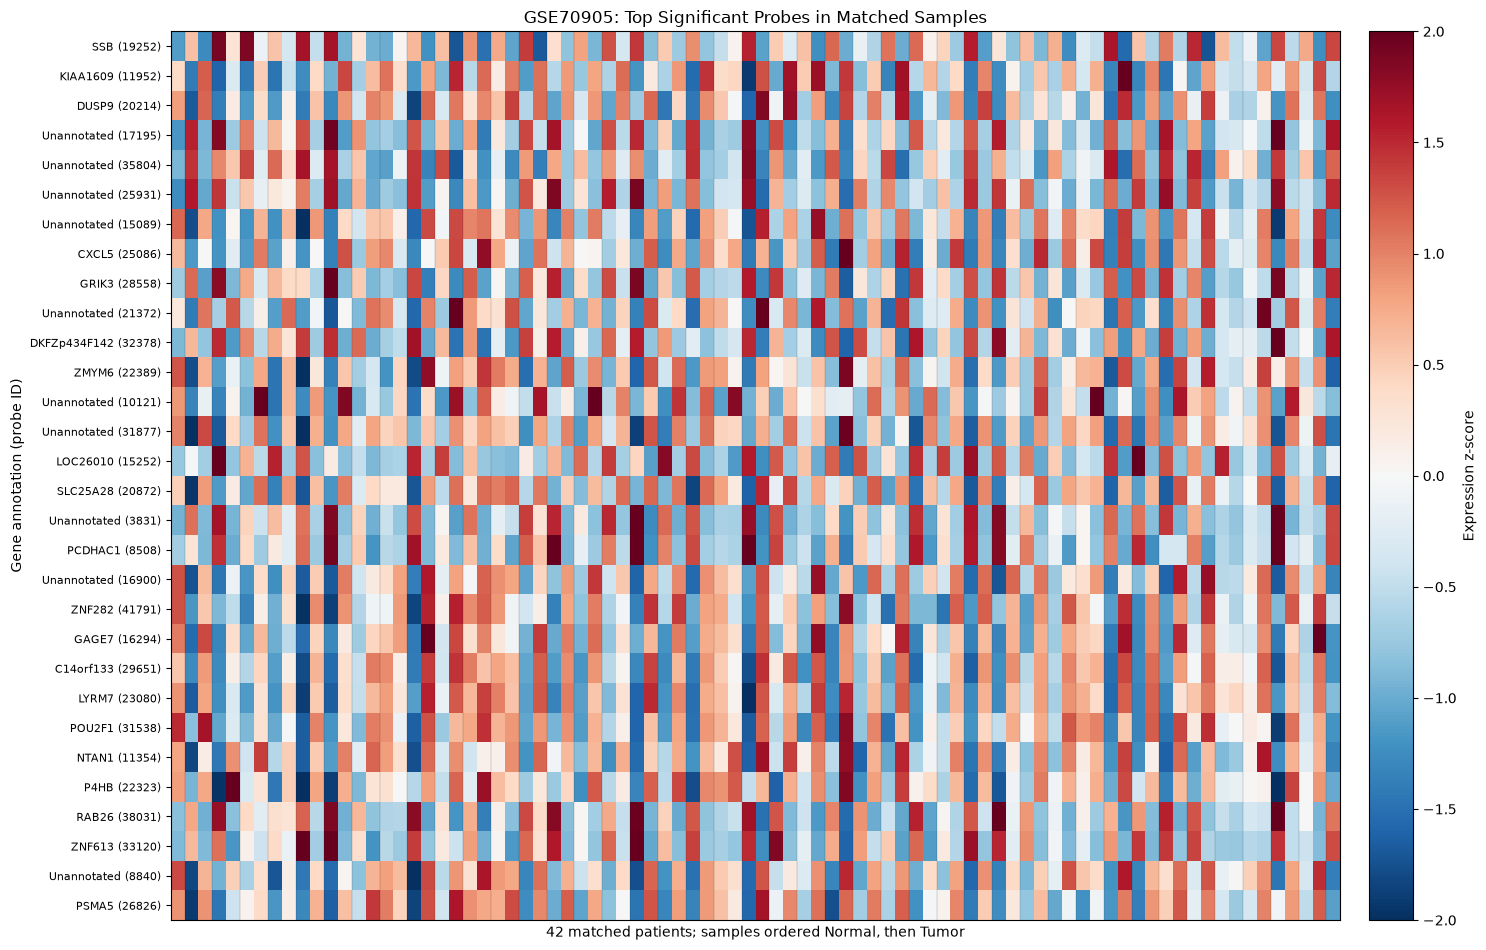

Heatmap saved to: c:\Users\NUMB1\Desktop\breast cancer bio\result\heatmap_top30_probes.png


In [42]:

top30 = significant.sort_values("FDR_paired").head(30).copy()


probe_to_row = pd.Series(
    np.arange(len(data)),
    index=data["ID_REF"].astype(str)
)

row_positions = top30["Probe_ID"].astype(str).map(probe_to_row)
valid_rows = row_positions.notna()

top30 = top30.loc[valid_rows].copy()
row_positions = row_positions.loc[valid_rows].astype(int)

meta = sample_info.copy()
meta["Patient_ID"] = meta["Sample_title"].str.extract(
    r"(CM\d+)", expand=False
)
meta["Condition"] = meta["Sample_title"].str.extract(
    r"(normal|tumor|reduction)$", expand=False
)

meta = meta[meta["Condition"].isin(["normal", "tumor"])].dropna(
    subset=["Patient_ID"]
)

normal_map = meta[meta["Condition"] == "normal"].set_index(
    "Patient_ID"
)["GSM_ID"]

tumor_map = meta[meta["Condition"] == "tumor"].set_index(
    "Patient_ID"
)["GSM_ID"]

patients = sorted(set(normal_map.index) & set(tumor_map.index))

sample_ids = [
    sample_id
    for patient in patients
    for sample_id in (normal_map.loc[patient], tumor_map.loc[patient])
]


heatmap_data = expression.iloc[row_positions.to_numpy()].loc[
    :, sample_ids
].copy()


heatmap_data.index = [
    f"{symbol if pd.notna(symbol) else 'Unannotated'} ({probe})"
    for symbol, probe in zip(top30["GENE_SYMBOL"], top30["Probe_ID"])
]

heatmap_data = heatmap_data.apply(pd.to_numeric, errors="coerce")
heatmap_data = heatmap_data.loc[heatmap_data.notna().any(axis=1)]

heatmap_data = heatmap_data.T.fillna(
    heatmap_data.median(axis=1)
).T

row_std = heatmap_data.std(axis=1, ddof=0).replace(0, np.nan)
z_scores = heatmap_data.sub(
    heatmap_data.mean(axis=1), axis=0
).div(row_std, axis=0)

z_scores = z_scores.dropna(axis=0, how="any")

fig, ax = plt.subplots(
    figsize=(16, max(8, len(z_scores) * 0.32))
)

image = ax.imshow(
    z_scores.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap="RdBu_r",
    vmin=-2,
    vmax=2
)

ax.set_yticks(np.arange(len(z_scores)))
ax.set_yticklabels(z_scores.index, fontsize=8)
ax.set_xticks([])


for x in range(1, len(sample_ids), 2):
    ax.axvline(x - 0.5, color="black", linewidth=0.35, alpha=0.3)

ax.set_title("GSE70905: Top Significant Probes in Matched Samples")
ax.set_xlabel(
    f"{len(patients)} matched patients; samples ordered Normal, then Tumor"
)
ax.set_ylabel("Gene annotation (probe ID)")

colorbar = fig.colorbar(image, ax=ax, pad=0.02)
colorbar.set_label("Expression z-score")

plt.tight_layout()

output_folder = Path.cwd().parent / "result"
output_folder.mkdir(parents=True, exist_ok=True)

heatmap_path = output_folder / "heatmap_top30_probes.png"
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

print("Heatmap saved to:", heatmap_path)

In [43]:
project_folder = Path.cwd().parent
data_folder = project_folder / "data"
output_folder = project_folder / "result"

required_files = [
    project_folder / "README.md",
    project_folder / ".gitignore",
    project_folder / "note book" / "breastcancerr.ipynb",
    data_folder / "GSE70905_series_matrix (1).txt",
    data_folder / "GPL4133_old_annotations.txt",
    output_folder / "limma_free_python_results.csv",
    output_folder / "significant_genes_python.csv",
    output_folder / "significant_annotated_genes.csv",
    output_folder / "top_10_significant_probes.csv",
    output_folder / "volcano_plot_python.png",
    output_folder / "heatmap_top30_probes.png"
]

missing = []

for file in required_files:
    if file.exists() and file.stat().st_size > 0:
        print("OK:", file.relative_to(project_folder))
    else:
        print("MISSING:", file.relative_to(project_folder))
        missing.append(file)

if missing:
    print(f"\n{len(missing)} file(s) need attention.")
else:
    print("\nAll required files exist and are non-empty.")

OK: README.md
OK: .gitignore
OK: note book\breastcancerr.ipynb
OK: data\GSE70905_series_matrix (1).txt
OK: data\GPL4133_old_annotations.txt
OK: result\limma_free_python_results.csv
OK: result\significant_genes_python.csv
OK: result\significant_annotated_genes.csv
OK: result\top_10_significant_probes.csv
OK: result\volcano_plot_python.png
OK: result\heatmap_top30_probes.png

All required files exist and are non-empty.


Condition
Normal       47
Tumor        47
Reduction    43
Name: count, dtype: int64


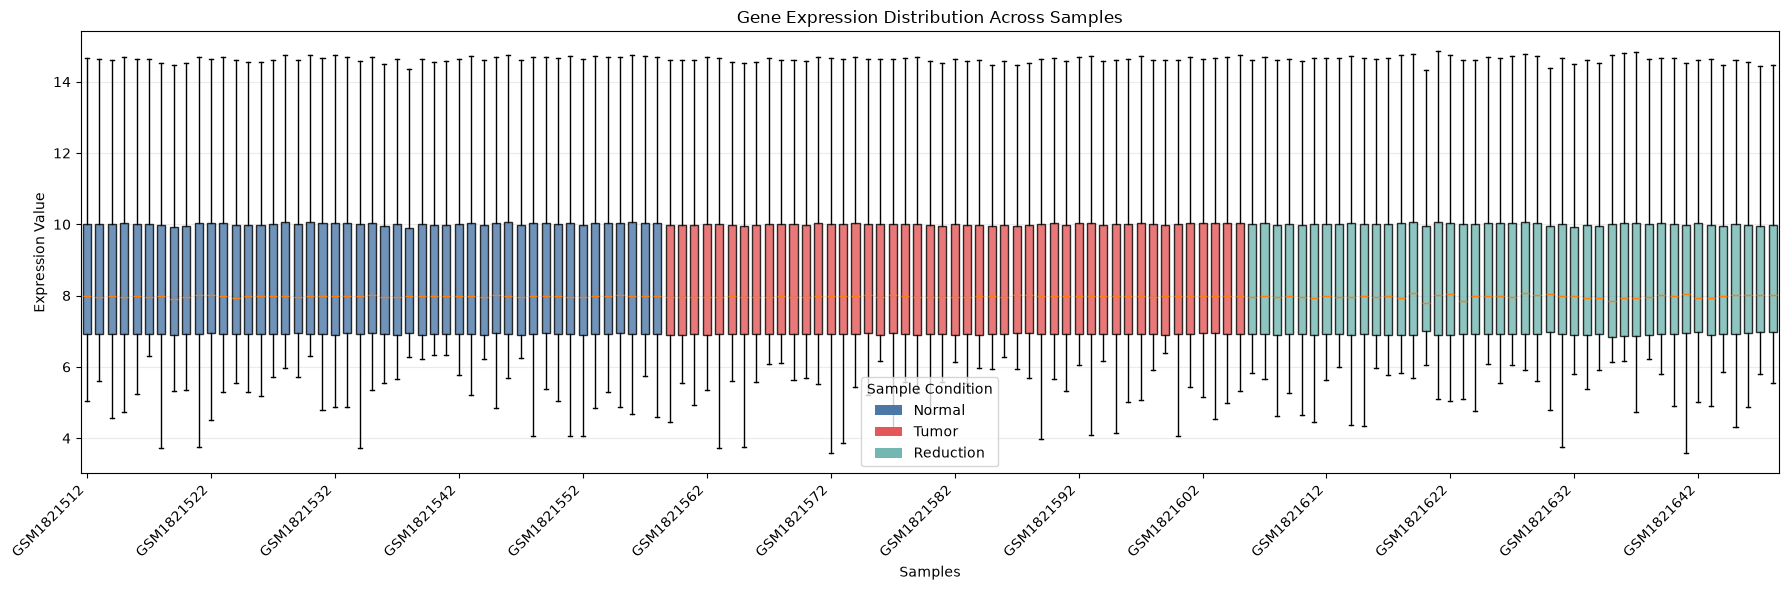

Saved to: c:\Users\NUMB1\Desktop\breast cancer bio\result\boxplot_sample_expression_distribution.png


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Set the results folder
result_folder = Path.cwd().parent / "result"
result_folder.mkdir(parents=True, exist_ok=True)
import pandas as pd

expression = pd.read_csv(
    result_folder / "expression_matrix_for_R.csv",
    index_col=0
)

sample_info = pd.read_csv(
    result_folder / "sample_info_for_R.csv"
)

# Identify the condition of each sample
sample_info["Condition"] = (
    sample_info["Sample_title"]
    .str.extract(r"(normal|tumor|reduction)$", expand=False)
    .str.title()
)

sample_info_indexed = (
    sample_info.set_index("GSM_ID")
    .reindex(expression.columns)
)

print(sample_info_indexed["Condition"].value_counts())

# Set colors for each condition
condition_colors = {
    "Normal": "#4C78A8",
    "Tumor": "#E45756",
    "Reduction": "#72B7B2"
}

# Collect expression values
plot_data = []

for sample in expression.columns:
    values = pd.to_numeric(
        expression[sample], errors="coerce"
    ).dropna().values

    plot_data.append(values)

# Set the color of each box
box_colors = [
    condition_colors.get(
        sample_info_indexed.loc[sample, "Condition"],
        "#999999"
    )
    for sample in expression.columns
]

# Draw the box plot
fig, ax = plt.subplots(figsize=(18, 6))

boxes = ax.boxplot(
    plot_data,
    patch_artist=True,
    showfliers=False,
    widths=0.65
)

for box, color in zip(boxes["boxes"], box_colors):
    box.set_facecolor(color)
    box.set_alpha(0.8)

ax.set_title("Gene Expression Distribution Across Samples")
ax.set_xlabel("Samples")
ax.set_ylabel("Expression Value")

ticks = list(range(1, len(expression.columns) + 1, 10))
ax.set_xticks(ticks)
ax.set_xticklabels(
    [expression.columns[i - 1] for i in ticks],
    rotation=45,
    ha="right"
)

present_conditions = [
    condition
    for condition in condition_colors
    if condition in sample_info_indexed["Condition"].dropna().unique()
]

legend_handles = [
    Patch(facecolor=condition_colors[c], label=c)
    for c in present_conditions
]

ax.legend(handles=legend_handles, title="Sample Condition")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

# Save the plot
plot_path = result_folder / "boxplot_sample_expression_distribution.png"
fig.savefig(plot_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Saved to:", plot_path)